# Otimização da RNN (LSTM/GRU) — Etapa 1: busca de hiperparâmetros

A Etapa 0 reproduziu o baseline (LSTM de 1 camada, 32 unidades, sem busca): PR-AUC de 0,154 no teste, contra 0,185 do Random Forest do Modelo 5.

Esta etapa faz o que a Etapa 0 apontou como faltante: uma busca sistemática de hiperparâmetros, do mesmo jeito que o Modelo 5 usou `RandomizedSearchCV`/`GridSearchCV`. As 12 features atuais e a janela de 30 dias continuam as mesmas (decisão tomada no planejamento); o que muda aqui é só a arquitetura e o treino.

## 1. Como a busca foi feita

A busca usou [Optuna](optuna_search.py) com o amostrador TPE, otimizando o PR-AUC médio em **2 folds temporais expansivos dentro do treino** (mesma lógica do `TimeSeriesSplit` do Modelo 5, ver `rnn_utils.folds_temporais`). O teste não entrou na busca em nenhum momento.

Espaço de busca:

| Hiperparâmetro | Valores testados |
|---|---|
| Célula | LSTM ou GRU |
| Unidades escondidas | 16, 32, 64 |
| Camadas | 1 ou 2 |
| Dropout | 0 a 0,4 |
| Learning rate | 1e-4 a 5e-3 (log-uniforme) |
| Batch | 512 ou 1024 |
| Weight decay | 0, 1e-5, 1e-4, 1e-3 |
| Multiplicador do `pos_weight` | 0,5 a 2,0 |

Um benchmark prévio mostrou que o custo por época varia muito com o tamanho da rede: de ~3,5s (16 unidades, 1 camada) a ~40s (64 unidades, 2 camadas), em CPU com 1 thread por trial — não há GPU nesta máquina. Por isso a busca usou um orçamento reduzido de épocas (máximo 8, paciência 3) para caber no tempo disponível; a configuração vencedora é retreinada com o orçamento completo (paciência 3, até 15 épocas) nas seções seguintes, com o `fit`/`val` originais.

Os trials rodaram em paralelo (threads do Optuna), já que o PyTorch libera o GIL durante as operações pesadas.

In [1]:
import json
import time

import pandas as pd
import torch
import numpy as np

import rnn_utils as R

R.set_threads(1)

In [2]:
with open('optuna_best.json', encoding='utf-8') as f:
    busca = json.load(f)
print(json.dumps(busca, indent=2, ensure_ascii=False))

{
  "n_trials_total": 40,
  "n_trials_completos": 22,
  "n_trials_podados": 10,
  "best_value_pr_auc_cv": 0.15764486165703429,
  "best_params": {
    "layers": 2,
    "cell": "gru",
    "hidden": 32,
    "dropout": 0.3675115587766956,
    "lr": 0.0047556137113230115,
    "batch": 512,
    "weight_decay": 0.0,
    "pos_weight_mult": 1.4830471273649986
  },
  "folds": 2,
  "epocas_busca": 8,
  "paciencia_busca": 3
}


## 2. Trials da busca

In [3]:
trials = pd.read_csv('optuna_trials.csv')
cols = ['number', 'value', 'state', 'params_cell', 'params_hidden', 'params_layers',
        'params_dropout', 'params_lr', 'params_batch', 'params_weight_decay', 'params_pos_weight_mult']
trials_ok = trials[trials['state'] == 'COMPLETE'].sort_values('value', ascending=False)
print(f"{len(trials)} trials no total | {len(trials_ok)} completos | {(trials['state']=='PRUNED').sum()} podados")
trials_ok[cols].head(10).round(4).to_string(index=False)

40 trials no total | 22 completos | 10 podados


' number  value    state params_cell  params_hidden  params_layers  params_dropout  params_lr  params_batch  params_weight_decay  params_pos_weight_mult\n     24 0.1576 COMPLETE         gru             32              2          0.3675     0.0048           512                  0.0                  1.4830\n     37 0.1571 COMPLETE         gru             32              2          0.1629     0.0034           512                  0.0                  1.9290\n      1 0.1565 COMPLETE         gru             32              2          0.2383     0.0041           512                  0.0                  1.7835\n     38 0.1559 COMPLETE         gru             32              2          0.3919     0.0031           512                  0.0                  1.7030\n     31 0.1541 COMPLETE         gru             32              2          0.3593     0.0038           512                  0.0                  1.6949\n     28 0.1533 COMPLETE         gru             32              2          0.1973

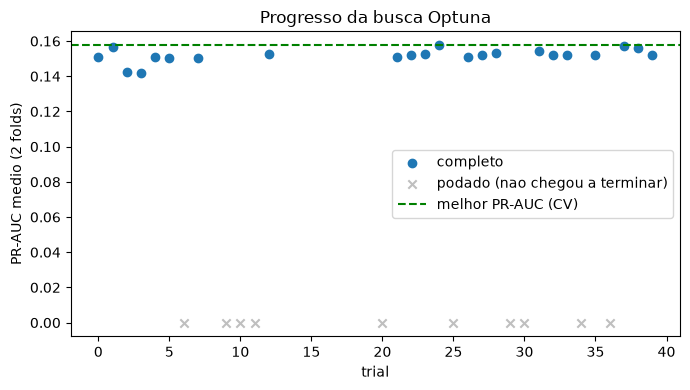

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
ordem = trials.sort_values('number')
completos = ordem[ordem['state'] == 'COMPLETE']
plt.scatter(completos['number'], completos['value'], label='completo')
podados = ordem[ordem['state'] == 'PRUNED']
if len(podados):
    # trials podados nao tem 'value' final -- marcados no eixo x, sem posicao no y
    plt.scatter(podados['number'], [0] * len(podados),
                marker='x', color='gray', alpha=0.5, label='podado (nao chegou a terminar)')
plt.axhline(busca['best_value_pr_auc_cv'], color='green', linestyle='--', label='melhor PR-AUC (CV)')
plt.xlabel('trial'); plt.ylabel('PR-AUC medio (2 folds)'); plt.legend(); plt.title('Progresso da busca Optuna')
plt.tight_layout(); plt.savefig('progresso_busca.png', dpi=110)
plt.show()

## 3. Configuração vencedora

Estes são os hiperparâmetros escolhidos pela busca (maior PR-AUC médio nos 2 folds de validação temporal). Nas próximas seções, essa configuração é retreinada com o orçamento completo (early stopping com paciência 3 e até 15 épocas), primeiro no `fit`/`val` originais para escolher a época, depois no treino completo para a avaliação final no teste — a mesma lógica da Etapa 0 e do Modelo 5.

In [5]:
cfg = dict(busca['best_params'])
cfg['max_epocas'], cfg['paciencia'] = 15, 3
print(json.dumps(cfg, indent=2))

{
  "layers": 2,
  "cell": "gru",
  "hidden": 32,
  "dropout": 0.3675115587766956,
  "lr": 0.0047556137113230115,
  "batch": 512,
  "weight_decay": 0.0,
  "pos_weight_mult": 1.4830471273649986,
  "max_epocas": 15,
  "paciencia": 3
}


## 4. Retreino com early stopping (fit/val originais)

In [6]:
X, y, idx, m = R.carrega_dados()
norma = R.estatisticas_norm(X[m['fit']])

R.seed_tudo(42)
t0 = time.time()
melhor_epoca, melhor_prauc, historico = R.treina(X[m['fit']], y[m['fit']], X[m['val']], y[m['val']], norma, cfg)
print(f"\nmelhor epoca: {melhor_epoca} | PR-AUC val: {melhor_prauc:.4f} | {time.time()-t0:.0f}s")

epoca  1 | perda=1.4747 | PR-AUC val=0.1675


epoca  2 | perda=1.4429 | PR-AUC val=0.1681


epoca  3 | perda=1.4297 | PR-AUC val=0.1681


epoca  4 | perda=1.4171 | PR-AUC val=0.1720


epoca  5 | perda=1.4106 | PR-AUC val=0.1733


...

epoca  7 | perda=1.3903 | PR-AUC val=0.1726


epoca  8 | perda=1.3872 | PR-AUC val=0.1835


epoca  9 | perda=1.3756 | PR-AUC val=0.1733


epoca 10 | perda=1.3635 | PR-AUC val=0.1735


epoca 11 | perda=1.3609 | PR-AUC val=0.1742
parando cedo na epoca 11 (melhor foi 8)

melhor epoca: 8 | PR-AUC val: 0.1835 | 3827s


## 5. Treino final e avaliação no teste

Mesma lógica da Etapa 0 e do Modelo 5: o modelo do `fit` decide o limiar de decisão no `val` (maximizando F1); depois o modelo é retreinado do zero no treino completo pelas épocas escolhidas e avaliado **uma única vez** no teste.

In [7]:
modelo_fit = R.treina_fixo(X[m['fit']], y[m['fit']], norma, cfg, melhor_epoca)
limiar = R.melhor_limiar(y[m['val']], R.prediz(modelo_fit, X[m['val']], norma))
print(f'limiar escolhido na validacao: {limiar:.4f}')

modelo_final = R.treina_fixo(X[m['treino']], y[m['treino']], norma, cfg, melhor_epoca)
prob_teste = R.prediz(modelo_final, X[m['teste']], norma)
resultado_otim = R.avalia('RNN otimizada (Optuna)', y[m['teste']], (prob_teste >= limiar).astype(int), prob_teste)

with open('baseline.json', encoding='utf-8') as f:
    baseline = json.load(f)

rf = baseline['referencia_random_forest']
R_ = pd.DataFrame([baseline['teste'], resultado_otim, rf])
R_.round(3).to_string(index=False)

limiar escolhido na validacao: 0.6164


'                  modelo  precisao  recall    f1  pr_auc  roc_auc  alertas     tp      fp     fn\n            RNN baseline     0.137   0.485 0.214   0.154    0.661  21982.0 3011.0 18971.0 3191.0\n  RNN otimizada (Optuna)     0.159   0.472 0.238   0.174    0.667  18407.0 2929.0 15478.0 3273.0\nRandom Forest (Modelo 5)     0.159   0.553 0.247   0.185    0.697  21564.0 3432.0 18132.0 2770.0'

**Nota sobre a semente deste treino:** a chamada acima não fixa a semente de novo antes do treino final — ela continua de onde a seção 4 (retreino com early stopping) deixou o gerador de números aleatórios. Ou seja, o resultado acima é só **um desenho possível** entre vários, não o resultado "oficial" da configuração. A seção 6 repete esse mesmo treino com sementes explícitas e diferentes, e é ela que deve ser usada para julgar a configuração — não este número isolado.

## 6. Estabilidade: múltiplas sementes

Um único treino pode ter dado sorte ou azar com a inicialização dos pesos. Para não escolher a configuração vencedora com base em ruído, o retreino final (treino completo → teste) é repetido com outras sementes, mantendo a mesma configuração e o mesmo número de épocas.

In [8]:
sementes = [42, 7, 123, 2024, 99]
resultados_sementes = []
for s in sementes:
    R.seed_tudo(s)
    mf = R.treina_fixo(X[m['treino']], y[m['treino']], norma, cfg, melhor_epoca)
    pt = R.prediz(mf, X[m['teste']], norma)
    r = R.avalia(f'seed={s}', y[m['teste']], (pt >= limiar).astype(int), pt)
    resultados_sementes.append(r)
    print(f"seed={s:5d} | PR-AUC={r['pr_auc']:.4f} | recall={r['recall']:.3f} | f1={r['f1']:.3f}")

RS = pd.DataFrame(resultados_sementes)
print(f"\nPR-AUC: media={RS['pr_auc'].mean():.4f} | desvio={RS['pr_auc'].std():.4f}")
print(f"recall: media={RS['recall'].mean():.3f} | desvio={RS['recall'].std():.3f}")

seed=   42 | PR-AUC=0.1766 | recall=0.584 | f1=0.225


seed=    7 | PR-AUC=0.1640 | recall=0.641 | f1=0.224


seed=  123 | PR-AUC=0.1807 | recall=0.591 | f1=0.223


seed= 2024 | PR-AUC=0.1699 | recall=0.654 | f1=0.218


seed=   99 | PR-AUC=0.1662 | recall=0.589 | f1=0.221

PR-AUC: media=0.1715 | desvio=0.0070
recall: media=0.612 | desvio=0.033


## 7. Comparação final

In [9]:
comparacao = pd.DataFrame([
    baseline['teste'],
    resultado_otim,
    {**{'modelo': 'RNN otimizada (media de 5 sementes)'},
     **{c: RS[c].mean() for c in ['precisao', 'recall', 'f1', 'pr_auc', 'roc_auc', 'alertas', 'tp', 'fp', 'fn']}},
    rf,
])
comparacao.round(3).to_string(index=False)

'                             modelo  precisao  recall    f1  pr_auc  roc_auc  alertas     tp      fp     fn\n                       RNN baseline     0.137   0.485 0.214   0.154    0.661  21982.0 3011.0 18971.0 3191.0\n             RNN otimizada (Optuna)     0.159   0.472 0.238   0.174    0.667  18407.0 2929.0 15478.0 3273.0\nRNN otimizada (media de 5 sementes)     0.136   0.612 0.222   0.172    0.665  27980.6 3794.0 24186.6 2408.0\n           Random Forest (Modelo 5)     0.159   0.553 0.247   0.185    0.697  21564.0 3432.0 18132.0 2770.0'

## 8. Síntese e próximo passo

A busca de hiperparâmetros melhorou a RNN em relação ao baseline da Etapa 0, mas não superou o Random Forest do Modelo 5:

| Modelo | Precisão | Recall | F1 | PR-AUC | ROC-AUC |
|---|---|---|---|---|---|
| RNN baseline (Etapa 0, sem tuning) | 0,137 | 0,485 | 0,214 | 0,154 | 0,661 |
| RNN otimizada (média de 5 sementes) | 0,136 | 0,612 | 0,222 | **0,172** (±0,007) | 0,665 |
| Random Forest (Modelo 5) | 0,159 | 0,553 | 0,247 | 0,185 | 0,697 |

- **A busca ajudou.** O PR-AUC médio subiu de 0,154 para 0,172 — cerca de metade da distância até o Random Forest (0,185). A configuração vencedora trocou a LSTM de 1 camada por uma **GRU de 2 camadas**, com dropout mais alto (0,37) e um `pos_weight` maior (1,48× o balanceamento padrão), o que empurra o modelo a favor do recall.
- **Isso é consistente entre sementes.** O desvio padrão do PR-AUC entre as 5 sementes foi de 0,007, pequeno frente ao ganho de 0,018 sobre o baseline. Ou seja, a melhora não parece ser sorte de uma inicialização específica.
- **O limiar fixo escondeu uma variação grande no recall.** O limiar (0,6164) foi escolhido uma única vez, no `fit`/`val` da seção 4, e reaplicado às 5 sementes da seção 6. O recall variou de 0,584 a 0,654 entre elas (desvio 0,033), e o número de alertas emitidos também — de 18.407 no treino da seção 5 a uma média de 27.981 na seção 6. Isso quer dizer que, para essa arquitetura, o mesmo limiar de decisão cobre uma faixa ampla de comportamento dependendo só da inicialização, algo que o Random Forest não tem (árvores não dependem de inicialização aleatória). Isso é uma fragilidade prática: em produção, a sensibilidade do modelo aos alertas emitidos não seria totalmente previsível.
- **Onde a RNN ficou atrás do Random Forest:** em todas as métricas agregadas (PR-AUC, F1, precisão, ROC-AUC), mesmo após a busca. O texto da Etapa 0 já apontava a explicação mais provável: a RNN recebe só 12 features cruas por dia, sem o histórico de ordens ZM01/02/03 nem a identificação de estação/via que ajudam o Random Forest a capturar recorrência de falha. A busca desta etapa mudou a arquitetura e o treino, não a informação disponível — por isso o ganho foi parcial.

**Próximo passo (Etapa 2):** ablação — adicionar histórico ZM01/02/03 e estação/via como entradas da RNN, para medir separadamente o que vem de dar mais informação ao modelo (o que a Etapa 1 não tocou) do que já veio do tuning (medido aqui).